# Phase 7: validation and mesh convergence

Generated by `scripts/validation_notebook.py` from the run database (`runs/runs.db`);
nothing in here is typed in by hand. Re-run that script (or this notebook in Jupyter,
from the repo root) to refresh it.

* **Mesh convergence**: baseline variant `baseline-0007`'s design point, meshed at three levels
  (studies `gci_coarse`, `gci_medium`, `gci_fine`). Each level ran the full pipeline (Gates 0-3).
  Only the blockMesh base cell size changes (2.5 m, 2.5/√2 m, 1.25 m); every snappyHexMesh level stays the same,
  so each level scales all cell sizes by r = √2. The domain is the same on every level (`mesh.domain_cell_size`).
* **GCI**: Celik et al. (2008), J. Fluids Eng. 130, 078001. Three grids, h = (V/N)^(1/3), observed order p,
  Richardson extrapolation, safety factor Fs = 1.25.
* **Batch mesh choice** (human decisions, 2026-11-25): see "Batch mesh level" below. The original 3 % rule on CL(4°)
  and the CL-α slope picked no level and was relaxed. CD is not used (see the end of this notebook).

In [1]:
import json, math
import matplotlib.pyplot as plt
import numpy as np
from aero import db
from aero import validation as V

con = db.connect("runs/runs.db")
STUDIES = {"fine": "gci_fine", "medium": "gci_medium", "coarse": "gci_coarse"}
GCI_LIMIT = 0.03
lv = V.level_table(con, STUDIES)
A_LO, A_HI = sorted(lv["fine"]["results"])
cfg = {k: lv[k]["mesh_cfg"] for k in V.LEVELS}
print("design point:", {k: round(v, 4) for k, v in lv["fine"]["params"].items()})

design point: {'span': 9.9531, 'sweep_le': 1.0325, 'taper': 0.6006, 'twist_tip': 1.8518, 'fuselage_fineness': 8.2122}


## Mesh levels and their runs

In [2]:
hdr = f"{'level':<8}{'base [m]':>9}{'cells':>9}{'skew':>6}{'nonorth':>8}{'status':>13}{'corr':>5}" \
      f"{'its a1':>7}{'its a2':>7}{'conv':>6}{'CL(%g)' % A_LO:>9}{'CL(%g)' % A_HI:>8}{'CD(%g)' % A_HI:>8}" \
      f"{'CLa /rad':>9}{'mesh s':>8}{'solve s':>8}"
print(hdr)
for k in reversed(V.LEVELS):
    s = lv[k]; r = s["results"]
    print(f"{k:<8}{cfg[k]['base_cell_size']:>9.4f}{int(s['cells']):>9}{s['max_skewness']:>6.2f}"
          f"{s['max_non_orth']:>8.1f}{s['status']:>13}{len(s['corrections']):>5}"
          f"{r[A_LO]['iterations']:>7}{r[A_HI]['iterations']:>7}"
          f"{'yes' if r[A_LO]['converged'] and r[A_HI]['converged'] else 'no':>6}"
          f"{r[A_LO]['CL']:>9.4f}{r[A_HI]['CL']:>8.4f}{r[A_HI]['CD']:>8.4f}{s['slope_cfd']:>9.3f}"
          f"{s['mesh_wall_s']:>8.0f}{s['solve_wall_s']:>8.0f}")
for k in reversed(V.LEVELS):
    for c in lv[k]["corrections"]:
        print(f"  correction on {k}: {c['gate']} {c['code']} {c['param']} {c['old']} -> {c['new']}")
print("max std(CL) over the Gate 3 window:",
      max(lv[k]["results"][a]["cl_std"] for k in V.LEVELS for a in (A_LO, A_HI)))

level    base [m]    cells  skew nonorth       status corr its a1 its a2  conv    CL(0)   CL(4)   CD(4) CLa /rad  mesh s solve s
coarse     2.5000    98736  3.63    51.9  CHECKS_PASS    0    935    401   yes  -0.0460  0.2667  0.0156    4.479      32     428
medium     1.7678   190449  3.85    47.5  CHECKS_PASS    0    701    401   yes  -0.0493  0.2694  0.0128    4.564      68     513
fine       1.2500   377136  3.77    48.1  CHECKS_PASS    0    958    401   yes  -0.0485  0.2719  0.0110    4.590     143    1004
max std(CL) over the Gate 3 window: 3.7678416104256537e-06


## GCI table

Two cell-size definitions, because snappyHexMesh levels are not geometrically similar: the transition bands are
`nCellsBetweenLevels` *cells* thick, so the near-surface bands get thinner as the mesh is refined, and N grows
about r² instead of r³. **cells**: Celik's h = (V/N)^(1/3). **geometric**: h = blockMesh base size. Every surface,
feature and box cell scales with it (r = √2). The batch criterion has to hold under both.

`p` observed order, `phi_ext` Richardson extrapolation, `GCI` = Fs·|φ_ext - φ_k|/|φ_k| on level k
(for the fine level this is Celik's GCI₂₁, for the medium level GCI₃₂ is shown). `asym` = GCI₃₂/(r₂₁ᵖ·GCI₂₁),
about 1 in the asymptotic range. A GCI is only computable for monotone convergence.

In [3]:
GS = {m: V.gci_study(lv, A_HI, A_LO, m) for m in ("cells", "geometric")}
G = GS["cells"]
pct = lambda v: "   -" if v is None else f"{100 * v:.2f}%"
num = lambda v, f: "-" if v is None else format(v, f)
for mode, GG in GS.items():
    g0 = GG["CL_alpha"]
    print(f"h = {'(V/N)^(1/3)' if mode == 'cells' else 'base cell size'}:  r21 = {g0.r21:.3f}, r32 = {g0.r32:.3f}")
    print(f"  {'quantity':<10}{'fine':>9}{'medium':>9}{'coarse':>9}{'conv':>12}{'p':>6}{'phi_ext':>9}"
          f"{'GCI fine':>10}{'GCI med':>9}{'GCI crs':>9}{'asym':>6}")
    for name, g in GG.items():
        print(f"  {name:<10}{g.phi[0]:>9.5f}{g.phi[1]:>9.5f}{g.phi[2]:>9.5f}{g.convergence:>12}"
              f"{num(g.p, '.2f'):>6}{num(g.phi_ext, '.5f'):>9}{pct(g.gci_fine):>10}{pct(g.gci_medium):>9}"
              f"{pct(g.gci_coarse):>9}{num(g.asymptotic, '.2f'):>6}")
    print()

h = (V/N)^(1/3):  r21 = 1.256, r32 = 1.245
  quantity       fine   medium   coarse        conv     p  phi_ext  GCI fine  GCI med  GCI crs  asym
  CL(4)       0.27191  0.26939  0.26670    monotone  0.45  0.29538    10.79%   12.06%   13.44%  1.01
  CL_alpha    4.59015  4.56450  4.47860    monotone  5.61  4.60006     0.27%    0.97%    3.39%  1.01
  CL(0)      -0.04854 -0.04928 -0.04596 oscillatory     -        -         -        -        -     -
  CD(4)       0.01098  0.01285  0.01557    monotone  1.87  0.00748    39.87%   52.23%   64.96%  0.85

h = base cell size:  r21 = 1.414, r32 = 1.414
  quantity       fine   medium   coarse        conv     p  phi_ext  GCI fine  GCI med  GCI crs  asym
  CL(4)       0.27191  0.26939  0.26670    monotone  0.18  0.31210    18.48%   19.82%   21.28%  1.01
  CL_alpha    4.59015  4.56450  4.47860    monotone  3.49  4.60107     0.30%    1.00%    3.42%  1.01
  CL(0)      -0.04854 -0.04928 -0.04596 oscillatory     -        -         -        -        -     -
 

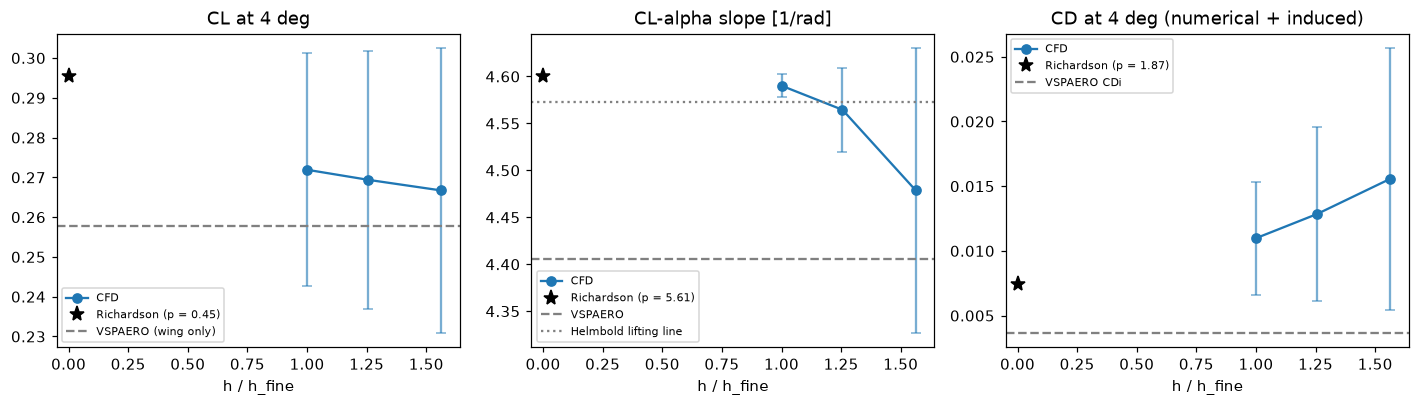

In [4]:
x = {k: (lv["fine"]["cells"] / lv[k]["cells"]) ** (1 / 3) for k in V.LEVELS}   # h / h_fine
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
def panel(ax, name, getter, title, refs=()):
    g = G[name]; xs = [x[k] for k in V.LEVELS]; ys = [getter(lv[k]) for k in V.LEVELS]
    ax.plot(xs, ys, "o-", label="CFD")
    if g.phi_ext is not None:
        ax.plot([0], [g.phi_ext], "k*", ms=10, label=f"Richardson (p = {g.p:.2f})")
        ax.errorbar(xs, ys, yerr=[(g.gci_at(k) or 0) * abs(y) for k, y in zip(V.LEVELS, ys)],
                    fmt="none", capsize=3, color="C0", alpha=.6)
    for lab, val, st in refs:
        ax.axhline(val, ls=st, color="gray", label=lab)
    ax.set_xlim(left=-0.05); ax.set_xlabel("h / h_fine"); ax.set_title(title); ax.legend(fontsize=7)
f, vref = lv["fine"], lv["fine"]["vspaero"]
panel(axs[0], f"CL({A_HI:g})", lambda s: s["results"][A_HI]["CL"], f"CL at {A_HI:g} deg",
      [("VSPAERO (wing only)", vref[A_HI]["CL"], "--")])
panel(axs[1], "CL_alpha", lambda s: s["slope_cfd"], "CL-alpha slope [1/rad]",
      [("VSPAERO", f["slope_vspaero"], "--"), ("Helmbold lifting line", f["slope_helmbold"], ":")])
panel(axs[2], f"CD({A_HI:g})", lambda s: s["results"][A_HI]["CD"], f"CD at {A_HI:g} deg (numerical + induced)",
      [("VSPAERO CDi", vref[A_HI]["CDi"], "--")])
fig.tight_layout()

## Batch mesh level

**Original rule** (human decision before the study): the coarsest level with GCI ≤ 3 % for CL(4°) and the CL-α slope,
under both cell-size definitions. **Relaxed rule** (human decision after seeing that no level meets the original
rule, 2026-11-25): CL-α GCI ≤ 3 % under both definitions **and** CL(4°) changes ≤ 1 % to the next finer level.

In [5]:
crit = {f"{n} [{m}]": GS[m][n] for m in GS for n in (f"CL({A_HI:g})", "CL_alpha")}
chosen_orig = V.choose_level(crit, GCI_LIMIT)
cl = {k: lv[k]["results"][A_HI]["CL"] for k in V.LEVELS}
chosen = V.choose_level_relaxed([GS[m]["CL_alpha"] for m in GS], cl, GCI_LIMIT, 0.01)
finer = {"coarse": "medium", "medium": "fine"}
for k in reversed(V.LEVELS):
    vals = ", ".join(f"{n} {pct(g.gci_at(k))}" for n, g in crit.items())
    dcl = f"{100 * abs(cl[k] - cl[finer[k]]) / abs(cl[finer[k]]):.2f}%" if k in finer else "-"
    wall = lv[k]["mesh_wall_s"] + lv[k]["solve_wall_s"] + (V.pilot_wall_s(con, lv[k]["run"]) or 0)
    print(f"{k:<7} GCI: {vals}\n        CL({A_HI:g}) change to next finer: {dcl}; cells {int(lv[k]['cells'])}, "
          f"mesh+pilot+prod wall {wall / 60:.1f} min (3 levels run concurrently)")
print("original rule:", chosen_orig or "no level qualifies")
print("relaxed rule: ", chosen or "no level qualifies (human decision needed)")
if chosen:
    print("frozen into configs/study_baseline.yaml (mesh):",
          {k: cfg[chosen][k] for k in ("base_cell_size", "domain_cell_size", "max_boundary_skewness",
                                       "surface_level", "feature_level", "near_body_level", "wake_level",
                                       "n_cells_between_levels")})

coarse  GCI: CL(4) [cells] 13.44%, CL_alpha [cells] 3.39%, CL(4) [geometric] 21.28%, CL_alpha [geometric] 3.42%
        CL(4) change to next finer: 1.00%; cells 98736, mesh+pilot+prod wall 10.4 min (3 levels run concurrently)
medium  GCI: CL(4) [cells] 12.06%, CL_alpha [cells] 0.97%, CL(4) [geometric] 19.82%, CL_alpha [geometric] 1.00%
        CL(4) change to next finer: 0.93%; cells 190449, mesh+pilot+prod wall 14.5 min (3 levels run concurrently)
fine    GCI: CL(4) [cells] 10.79%, CL_alpha [cells] 0.27%, CL(4) [geometric] 18.48%, CL_alpha [geometric] 0.30%
        CL(4) change to next finer: -; cells 377136, mesh+pilot+prod wall 27.4 min (3 levels run concurrently)
original rule: no level qualifies
relaxed rule:  medium
frozen into configs/study_baseline.yaml (mesh): {'base_cell_size': 1.767767, 'domain_cell_size': 2.5, 'max_boundary_skewness': 4.0, 'surface_level': [5, 6], 'feature_level': 6, 'near_body_level': 3, 'wake_level': 3, 'n_cells_between_levels': 3}


## CL-α slope: CFD vs VSPAERO vs lifting line (baseline study, 10 runs)

CFD slope from the two alphas of each baseline run (0° and 4°, coarse mesh as the baseline ran it).
VSPAERO: vortex lattice on the **wing only** (decision G4). Helmbold: lifting-line estimate for a straight-tapered
wing with a₀ = 2π and half-chord sweep, also wing only. The CFD includes the fuselage (carry-over lift and the
wing-body junction), so it does not have to match either estimate exactly.

run                AR  taper  sweep     CFD  VSPAERO Helmbold CFD/VSP CFD/Helm
baseline-0001    6.45   0.26    6.6   4.628    4.505    4.624   1.027    1.001
baseline-0002    6.87   0.34    0.2   4.699    4.586    4.683   1.024    1.003
baseline-0003    5.74   0.88    2.1   4.452    4.208    4.465   1.058    0.997
baseline-0004    7.12   0.70    8.4   4.678    4.537    4.744   1.031    0.986
baseline-0005    9.66   0.40    3.6   5.196    5.002    5.114   1.039    1.016
baseline-0006    5.87   0.55    4.5   4.456    4.330    4.497   1.029    0.991
baseline-0007    6.22   0.60    1.0   4.454    4.355    4.573   1.023    0.974
baseline-0008    6.76   0.96    9.9   4.659    4.367    4.647   1.067    1.002
baseline-0009    6.98   0.80    5.2   4.828    4.450    4.729   1.085    1.021
baseline-0010    6.34   0.75    7.6   4.583    4.319    4.594   1.061    0.998
CFD/VSPAERO: mean 1.044, range 1.023-1.085
CFD/Helmbold: mean 0.999, range 0.974-1.021
baseline-0007 point: coarse-mesh slope 4.454

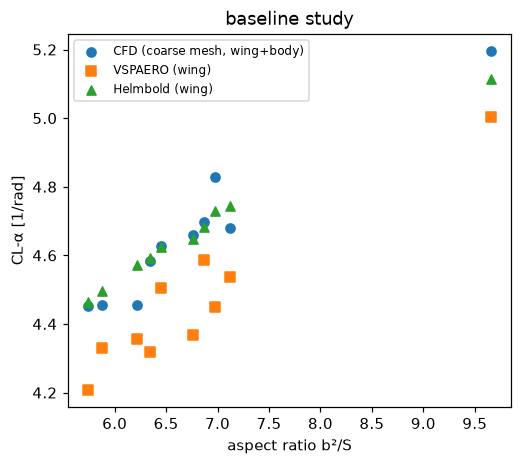

In [6]:
B = V.baseline_slopes(con, "baseline")
print(f"{'run':<15}{'AR':>6}{'taper':>7}{'sweep':>7}{'CFD':>8}{'VSPAERO':>9}{'Helmbold':>9}{'CFD/VSP':>8}{'CFD/Helm':>9}")
for s in B:
    p = s["params"]
    print(f"{s['run']:<15}{s['span']**2 / s['sref_full']:>6.2f}{p['taper']:>7.2f}{p['sweep_le']:>7.1f}"
          f"{s['slope_cfd']:>8.3f}{s['slope_vspaero']:>9.3f}{s['slope_helmbold']:>9.3f}"
          f"{s['slope_cfd'] / s['slope_vspaero']:>8.3f}{s['slope_cfd'] / s['slope_helmbold']:>9.3f}")
rv = np.array([s["slope_cfd"] / s["slope_vspaero"] for s in B])
rh = np.array([s["slope_cfd"] / s["slope_helmbold"] for s in B])
print(f"CFD/VSPAERO: mean {rv.mean():.3f}, range {rv.min():.3f}-{rv.max():.3f}")
print(f"CFD/Helmbold: mean {rh.mean():.3f}, range {rh.min():.3f}-{rh.max():.3f}")
g = G["CL_alpha"]
if g.phi_ext is not None:
    s7 = next(s for s in B if s["run"] == "baseline-0007")
    print(f"baseline-0007 point: coarse-mesh slope {s7['slope_cfd']:.3f}, mesh-converged (Richardson) "
          f"{g.phi_ext:.3f}, VSPAERO {s7['slope_vspaero']:.3f}, Helmbold {s7['slope_helmbold']:.3f}")
fig, ax = plt.subplots(figsize=(5.2, 4.4))
ar = [s["span"] ** 2 / s["sref_full"] for s in B]
ax.scatter(ar, [s["slope_cfd"] for s in B], label="CFD (coarse mesh, wing+body)")
ax.scatter(ar, [s["slope_vspaero"] for s in B], marker="s", label="VSPAERO (wing)")
ax.scatter(ar, [s["slope_helmbold"] for s in B], marker="^", label="Helmbold (wing)")
ax.set_xlabel("aspect ratio b²/S"); ax.set_ylabel("CL-α [1/rad]"); ax.legend(fontsize=8)
ax.set_title("baseline study")

## Why inviscid CD is not physical drag

Physics v1 uses slip walls and a tiny viscosity, so there is no skin friction and no boundary layer. A converged
inviscid solution on a perfect mesh would have only **induced drag** (plus zero pressure drag, d'Alembert). The CD the
solver reports also contains **numerical (spurious) drag**: entropy-like losses from discretization error at
the leading edge, the sharp trailing edge and the faceted surface. That part should shrink with mesh refinement. The
table below compares CFD CD with VSPAERO's induced drag CDi on the same planform. Whatever remains above CDi
after extrapolation is still not physical drag. Any result that uses CD from this pipeline must say so.
Friction and form drag need the viscous v2 (Phase 11).

In [7]:
for k in reversed(V.LEVELS):
    r = lv[k]["results"][A_HI]
    print(f"{k:<7} CD({A_HI:g}) = {r['CD']:.5f}   CDi VSPAERO = {lv[k]['vspaero'][A_HI]['CDi']:.5f}   "
          f"ratio {r['CD'] / lv[k]['vspaero'][A_HI]['CDi']:.2f}")
g = G[f"CD({A_HI:g})"]
print(f"CD convergence: {g.convergence}, p = {num(g.p, '.2f')}, Richardson CD = {num(g.phi_ext, '.5f')}")

coarse  CD(4) = 0.01557   CDi VSPAERO = 0.00365   ratio 4.26
medium  CD(4) = 0.01285   CDi VSPAERO = 0.00365   ratio 3.52
fine    CD(4) = 0.01098   CDi VSPAERO = 0.00365   ratio 3.01
CD convergence: monotone, p = 1.87, Richardson CD = 0.00748


## P6-3: SKEWNESS_HIGH correction sequence

Experiment `scripts/p63_skewness.py`. The 9 harsh-study runs that ended UNRECOVERABLE with SKEWNESS_HIGH were
re-meshed in `runs/_experiments/p63/` from their **initial** settings with one variant each. Gate 1 was
evaluated on the result (same code as the pipeline). `base` reproduces each run's original attempt 0.
Data: `notebooks/data/p63_skewness.json` (parsed checkMesh / snappyHexMesh output).

In [8]:
P = json.load(open("notebooks/data/p63_skewness.json"))
runs = sorted({d["run"] for d in P}); variants = list(dict.fromkeys(d["variant"] for d in P))
idx = {(d["run"], d["variant"]): d for d in P}
print(f"{'variant':<16}" + "".join(f"{r[-4:]:>7}" for r in runs) + f"{'pass':>6}{'ratio min':>10}{'cells x':>8}")
for v in variants:
    ds = [idx[(r, v)] for r in runs if (r, v) in idx]
    cells = np.mean([d["cells"] / idx[(d["run"], "base")]["cells"] for d in ds])
    print(f"{v:<16}" + "".join(f"{idx[(r, v)]['max_skewness']:>7.2f}" if (r, v) in idx else f"{'':>7}" for r in runs)
          + f"{sum(d['gate1_pass'] for d in ds):>4}/{len(ds)}"
          + f"{min(d['area_ratio'] or 0 for d in ds):>10.4f}{cells:>8.3f}")
print("cells: max skewness (limit 4); pass = Gate 1 pass; ratio = snapped/STL wetted area (limit 0.98)")

variant            0002   0003   0004   0007   0011   0012   0014   0016   0018  pass ratio min cells x
base               6.35   5.91   8.01   5.05   9.15   4.90   4.10   4.80   9.25   0/9    0.9980   1.000
smooth5            4.16   5.16  13.71   5.67   4.22   5.13   4.19   4.21   8.88   0/9    0.9980   1.000
ncbl4              6.35   5.90   8.02   5.05   9.15   4.89   4.09   4.79   9.25   0/9    0.9981   1.279
relax10            6.39   5.96   8.01   6.09   8.82   4.94   4.21   4.80   9.25   0/9    0.9981   1.000
bskew4             3.83   3.88   3.92   3.88   3.83   3.74   3.54   3.97   3.88   9/9    0.9980   1.000
fsnap20            8.01   7.14   2.97   6.26   7.32   5.69   5.26   4.41  19.74   1/9    0.9981   1.000
tol1               6.35   5.89   8.01   5.05   9.15   4.90   4.10   4.51   9.25   0/9    0.9981   1.000
bskew4_smooth5     3.65   3.96   3.88   3.85   3.40   3.78   3.96   3.95   3.99   9/9    0.9980   1.000
bskew3             2.93   2.97   2.84   2.97   2.96   2.93   2.9

**Regression check**: the 19 runs that pass in `baseline` and `harsh` (10 + 9) were re-meshed from their initial
settings with the boundary-skewness limit set to 4 and to 3 (`notebooks/data/p63_regression.json`). They are
compared with their final Gate 1 values in the run DB.

In [9]:
R = json.load(open("notebooks/data/p63_regression.json"))
def last(run, m):
    return con.execute("SELECT value FROM gate_results WHERE run=? AND gate='gate1' AND metric=? "
                       "ORDER BY attempt DESC, id DESC LIMIT 1", (run, m)).fetchone()[0]
for v in dict.fromkeys(d["variant"] for d in R):
    ds = [d for d in R if d["variant"] == v]
    dr = [d["area_ratio"] - last(d["run"], "wetted_area_ratio") for d in ds]
    dc = [d["cells"] / last(d["run"], "cells_max") for d in ds]
    print(f"{v:<8} Gate 1 pass {sum(d['gate1_pass'] for d in ds)}/{len(ds)}, max skewness "
          f"{min(d['max_skewness'] for d in ds):.2f}-{max(d['max_skewness'] for d in ds):.2f}, "
          f"area ratio change {min(dr):+.5f} to {max(dr):+.5f}, cells x {min(dc):.3f}-{max(dc):.3f}")

bskew4   Gate 1 pass 19/19, max skewness 2.02-3.86, area ratio change -0.00006 to +0.00018, cells x 1.000-1.000
bskew3   Gate 1 pass 19/19, max skewness 2.02-3.00, area ratio change -0.00011 to +0.00015, cells x 1.000-1.000
